# Avazu Click Prediction : EDA

In [1]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from summarytools import dfSummary

### Changing some QoL settings.

In [2]:
import matplotlib
%matplotlib inline

import plotly.io as pio
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10,6)
plt.rcParams.update({
    "figure.facecolor": "black",
    "axes.facecolor": "black",
    "text.color": "white",
    "axes.labelcolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "grid.color": "gray",
    "savefig.facecolor": "black",
})

pio.templates["plotly_dark"].layout.paper_bgcolor = "black"
pio.templates["plotly_dark"].layout.plot_bgcolor = "black"
pio.templates.default = "plotly_dark"

## 1. Business Understanding
### An ad platform shows ads on websites and apps and gets paid when an ad is clicked.
### Problem : find which impressions are likely to be clicked , so budget goes to the impressions that pay.
### Target variable : `click` (1 = clicked , 0 = not clicked). This is binary classification.
### Questions :
### 1. What share of impressions get clicked (CTR) ?
### 2. Which devices , apps , sites , ad positions and hours have a higher CTR ?
### 3. Can a model rank impressions by click chance better than a guess ?
### 4. Where should the ad budget go ?

## 2. Dataset Summary and EDA
### Avazu click logs , 10 days (21 to 30 Oct 2014) , already split into train , valid and test (80 / 10 / 10).
### Sampling : the three files are 6.3 GB (40 million rows). Every 32nd row of each file is kept , about 1 million train rows.
### The rows are in time order , so the sample covers every hour of the 10 days.

In [3]:
# read the zip in chunks , count every row , keep every 32nd one
# chunksize is a multiple of 32 , so the pattern carries across chunks
if not os.path.exists('../../data/ctr/train_sample.parquet'):
    os.makedirs('../../data/ctr' , exist_ok=True)
    sizes = {}
    with zipfile.ZipFile('../../data/Dataset1.zip') as z:
        for split in ['train' , 'valid' , 'test']:
            rows , clicks , parts = 0 , 0 , []
            for chunk in pd.read_csv(z.open(f'{split}.csv') , dtype=str , chunksize=1_000_000):
                rows += len(chunk)
                clicks += (chunk['click'] == '1').sum()
                parts.append(chunk.iloc[::32])
            s = pd.concat(parts , ignore_index=True)
            s['click'] = s['click'].astype(int)
            s.to_parquet(f'../../data/ctr/{split}_sample.parquet' , index=False)
            sizes[split] = {'rows' : rows , 'ctr' : clicks / rows , 'sample rows' : len(s)}
    pd.DataFrame(sizes).T.to_csv('../../data/ctr/sizes.csv')

pd.read_csv('../../data/ctr/sizes.csv' , index_col=0)

,rows,ctr,sample rows
train,32343172.0,0.169806,1010725.0
valid,4042897.0,0.169806,126341.0
test,4042898.0,0.169806,126341.0


### 40.4 million impressions. The CTR is 16.98% in all three files , so the split looks stratified on click.

In [4]:
df = pd.read_parquet('../../data/ctr/train_sample.parquet')
df.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21
0,10002028568167339219,0,14102100,1005,0,9e8cf15d,0d3cb7be,f028772b,ecad2386,7801e8d9,...,1,2,20596,320,50,2161,0,35,100148,157
1,10047913575991848385,0,14102100,1010,1,85f751fd,c4e18dd6,50e219e0,c776ba2a,7801e8d9,...,4,0,21309,320,50,2449,0,163,100105,91
2,10095715444202916801,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,0,15701,320,50,1722,0,35,100084,79
3,10140638728626459396,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,0,15699,320,50,1722,0,35,-1,79
4,10203175855166128439,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,53de0284,d9b5648e,...,1,0,19743,320,50,2264,3,427,100000,61


In [5]:
df.shape

(1010725, 24)

### Summary tool

In [6]:
dfSummary(df.drop(columns='id'))

No,Variable,Stats / Values,Freqs / (% of Valid),Graph,Missing
1,click[int64],1. 02. 1,"839,108 (83.0%)171,617 (17.0%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAJsAAAAuCAYAAAA/ZmtKAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjgsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvwVt1zgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAAS5JREFUeJzt20Fqg1AYReFrkdBMFBFcTBbRxXYR7kbEN2hCJnbQNbzjg55vA38gJ4EEb3eeZyRCl+Se5Hb1C9Gl3ud5Pmsf6ed5/hqGYap9SO0qpexd133XDq4fhmF6PB7PcRxfNQ+pTcdxfK7rOm3bdktSN7YkGcfxtSzLT81DatqdOPJBHJESYxPI2IQxNmGMTRhjE8bYhDE2YYxNGGMTxtiEMTZhjE0YYxPG2ITpk78H6K5+IboG+d73pZR9Xdcp0AN0ak8pZU/yrn3HwYsSaPDSOeUThfxmQz49ahc25aPmYmoXMuUj52JqFznl89fuP+efusIYmzDGJoyxCWNswhibMMYmjLEJY2zCGJswxiaMsQljbMIYmzDGJgwy5XMqqASc8lFzMbXLwYswvwpbat8HENV8AAAAAElFTkSuQmCC"">",0(0.0%)
2,hour[object],1. 141022092. 141022103. 141028134. 141022125. 141028146. 141022117. 141030048. 141028099. 1410221310. 1410220811. other,"11,210 (1.1%)10,962 (1.1%)10,814 (1.1%)10,221 (1.0%)9,687 (1.0%)9,665 (1.0%)8,698 (0.9%)8,207 (0.8%)8,091 (0.8%)8,073 (0.8%)915,097 (90.5%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAJsAAAD+CAYAAAAtWHdlAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjgsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvwVt1zgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAA75JREFUeJzt3EFOI1cYRtHfltUJk7IsSyyDBbAIFptFeAHsAyFqEDpMyKDpcdJ0fB25z5kj1eDq2S69j837+/tAYXvpB+DXITYyYiMjNjJiIyM2MmIjIzYyYiOzmZmbmfkyM2/v7++vF34ertjueDw+LMtyWNf1ebPZ/CE4zmW7LMvh7u5ulmU5zLcTDs5iOzNzc3Pz16UfhOvnBwIZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRERsZsZHZzsy8vr7+dukH4fpt13V9fnx8nHVdn2fm7dIPxPWyQSCz8S+zqDjZyFhXkbGuImNdRcZLXTJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjIGL2QMXsi4Fk7G4IWMk42MwQsZgxcyBi9kvNQlIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjY/BCxuCFjGvhZAxeyPiBQMbHKBnrKjLWVWSsq8j4gUBGbGTERkZsZMRGRmxkxEZGbGTERkZsZMRGRmxkxEbGuoqMdRUZ18LJWFeR+X6yjVONc9sdj8eHmRljF85tuyzLwdiFgvdsZMRGRmxkxEZGbGTERkZsZMRGRmxkxEZGbGTERkZsZMRGRmxkdh9DlxljF87MtXAyBi9knGxkDF7IGLyQ8eqDjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MhYV5GxQSBjXUXGyUbGuoqMdRUZrz7IiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MgYvJBxLZyMwQsZJxsZgxcyBi9kvPogIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyYiNj8ELGtXAyBi9kfGcj42OUjHUVGesqMr6zkREbGbGRERsZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRsa4i41o4GesqMk42MgYvZAxeyHj1QUZsZMRGRmxkxEZGbGTERkZsZMRGRmxkxEZGbGTERkZsZMRGxuCFjGvhZAxeyHw/2VwJ5996++yn4O54PD58bBDgH63r+vzZcdRuWZbD/f39636//3qOh+N6vLy8/H46nQ5PT09fZubHY5uZ2e/3X29vb//8z5+Oa3Tz2T/0no2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI3Mbubb1ZFLPwj/fz/byW5d1+fT6XSYn7g6wq/jYyD1qXGUa+H8qE9fCzd4IeMHAhmxkREbGbGRERsZsZERGxmxkREbmb8BX7lTM9tcCdkAAAAASUVORK5CYII="">",0(0.0%)
3,C1[object],1. 10052. 10023. 10104. 10125. 10076. 10017. 1008,"928,427 (91.9%)55,434 (5.5%)22,747 (2.3%)2,905 (0.3%)838 (0.1%)236 (0.0%)138 (0.0%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAJsAAAChCAYAAADQgM1HAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjgsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvwVt1zgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAArpJREFUeJzt3T1uE1sAhuEzVsSFxlYUKUuAPXgRLJZFeBHsIYoyBeHSmIIfgRtsw7wW5nm6FJZO8cpHY82nTPv9fkBhdekD8O8QGxmxkREbGbGRmcYYr8YYLy59EP46n/b7/fMpH7i5u7t7u16vb5c6EddpnufHaZrenRLczXq9vt1ut8+bzebjkofjejw9Pb3c7Xa3Dw8PL8YYx8c2xhibzebj/f39h8VOxzV6deoHPCCQERsZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRuRnjyysjlz4If49ze7mZ5/lxt9vdjjNeGeHfNc/z4xjj0ymf8Vo45zr5tfDJIp7Ksd9sJ1cMh44avJwzboBDvxy8nDtugEPHDl48qfLb/KhLRmxkxEZGbGTERkZsZMRGRmxkxEZGbGTERkZsZMRGRmxkfrmusrziTzlqXXXOkgYO2SCQsa4ic/jN5huMxfy0rrKiYkmrb+uq7Xb7/DU663gW8X1d9fVvKyoW40ddMmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2Mv6dEJkfBy+GLSzKa+FkDF7IeEAgIzYyq2ma3kzT5GmUxa3GGK/HGP9d+iBcP9coGbGRERsZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRERuZ1Rjj/Rjj/0sfhOtn8ELGNUpGbGQMXsgYvJBxjZIRGxmxkREbGbGRERsZsZERGxmxkREbGbGRERsZsZERGxmxkTF4IWPwQsY1SkZsZMRGxrqKjHUVGdcoGbGRERsZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRERsZ6yoy1lVkXKNkxEbG4IWMwQsZ1ygZsZERGxmxkREbGbGRERsZsZERGxmxkREbGbGRERsZsZERGxmxkbGuImNdRcY1SkZsZMRGRmxkxEbmM28ErGc8AUM/AAAAAElFTkSuQmCC"">",0(0.0%)
4,banner_pos[object],1. 02. 13. 74. 25. 46. 57. 3,"727,556 (72.0%)281,350 (27.8%)1,136 (0.1%)331 (0.

### Variables
| column | meaning | relevance |
|---|---|---|
| id | row key | none , dropped |
| click | 1 if the ad was clicked | target |
| hour | YYMMDDHH of the impression | hour of day and weekday |
| C1 | anonymised category | follows device_type |
| banner_pos | where the ad sits on the screen | position should change clicks |
| site_id , site_domain , site_category | the website showing the ad (hashed) | where the ad is shown |
| app_id , app_domain , app_category | the app showing the ad (hashed) | where the ad is shown |
| device_id , device_ip | the user's device and IP (hashed) | identify a user , not a kind of impression |
| device_model , device_type , device_conn_type | phone model , kind of device , kind of connection | who sees the ad |
| C14 to C21 | anonymised categories (C15 x C16 look like the banner size) | ad and placement details |

In [7]:
df.dtypes

id                  object
click                int64
hour                object
C1                  object
banner_pos          object
site_id             object
site_domain         object
site_category       object
app_id              object
app_domain          object
app_category        object
device_id           object
device_ip           object
device_model        object
device_type         object
device_conn_type    object
C14                 object
C15                 object
C16                 object
C17                 object
C18                 object
C19                 object
C20                 object
C21                 object
dtype: object

In [8]:
df.nunique().sort_values()

click                     2
device_type               4
device_conn_type          4
C18                       4
banner_pos                7
C1                        7
C15                       8
C16                       9
site_category            22
app_category             25
C21                      60
C19                      67
C20                     164
app_domain              199
hour                    240
C17                     423
C14                    2259
site_id                2663
site_domain            2865
app_id                 3142
device_model           5194
device_id            151807
device_ip            559488
id                  1010725
dtype: int64

### Every column is a category stored as a code or a hash , even the ones that look like numbers (C15 = 320 is a banner width , not a quantity).
### device_ip and device_id have hundreds of thousands of levels. They point at single users , not at a type of impression.

### Missing values

In [9]:
df.isna().sum().sum()

np.int64(0)

In [10]:
(df['device_id'] == 'a99f214a').mean() , (df['C20'] == '-1').mean()

(np.float64(0.8251364119814985), np.float64(0.4691008929233966))

### No NaNs , but some values are placeholders : device_id a99f214a is on 82% of rows (anonymous device) and C20 is -1 on 47%.
### They stay as their own level , like 'unknown' in a normal dataset.

### Duplicates

In [11]:
df.drop(columns='id').duplicated().sum()

np.int64(37858)

### 3.7% of rows repeat another row without the id. They are separate impressions that look the same , so they stay.

### Class distribution

In [12]:
counts = df['click'].value_counts()
fig = px.bar(x=counts.index.astype(str) , y=counts.values , labels={'x' : 'click' , 'y' : 'count'} , title='click')
fig.show()
df['click'].value_counts(normalize=True)

click
0    0.830204
1    0.169796
Name: proportion, dtype: float64

### 17% clicked. Always guessing "no click" already gets 83% accuracy , so accuracy is not used.
### Log loss , ROC-AUC and PR-AUC are used instead.

### CTR across features
### Each bar is the CTR of one level , the dashed line is the overall CTR.

In [13]:
def ctr(col , top=None):
    g = df.groupby(col)['click'].agg(['mean' , 'size']).rename(columns={'mean' : 'ctr' , 'size' : 'impressions'})
    if top:
        g = g.sort_values('impressions' , ascending=False).head(top)
    fig = px.bar(g.reset_index() , x=col , y='ctr' , hover_data=['impressions'] , title=f'CTR by {col}')
    fig.add_hline(y=df['click'].mean() , line_dash='dash')
    fig.update_xaxes(type='category')
    fig.show()
    return g.round(3).T

### Device

In [14]:
ctr('device_type')

device_type,0,1,4,5
ctr,0.211,0.169,0.091,0.095
impressions,55434.000,932544.000,19488.000,3259.000


### device_type 1 (phones) is 92% of the traffic at 17%. Type 0 clicks more (21%) , types 4 and 5 click about half as much (9%).

In [15]:
ctr('device_conn_type')

device_conn_type,0,2,3,5
ctr,0.181,0.136,0.046,0.031
impressions,872107.000,82954.000,54596.000,1068.000


### Connection type 0 (86% of rows) has 18% CTR. Types 3 and 5 are below 5%.

### App vs website
### site_id 85f751fd is a placeholder that means the ad was shown inside an app.

In [16]:
df['traffic'] = (df['site_id'] == '85f751fd').map({True : 'app' , False : 'site'})
ctr('traffic')

traffic,app,site
ctr,0.119,0.199
impressions,365398.000,645327.000


### Ads on websites get clicked more (20%) than ads inside apps (12%).

In [17]:
ctr('app_category' , top=8)

app_category,07d7df22,0f2161f8,cef3e649,8ded1f7a,f95efa07,d1327cf5,dc97ec06,09481d60
ctr,0.199,0.109,0.093,0.09,0.248,0.124,0.155,0.144
impressions,653658.000,239773.000,43248.000,36786.00,28309.000,3003.000,1371.000,1337.000


In [18]:
ctr('site_category' , top=8)

site_category,50e219e0,f028772b,28905ebd,3e814130,f66779e6,75fa27f6,335d28a8,76b2941d
ctr,0.129,0.18,0.208,0.282,0.039,0.114,0.088,0.03
impressions,413833.000,316738.00,184406.000,75729.000,6180.000,3924.000,3395.000,2611.00


### Categories differ a lot : site category 3e814130 has 28% CTR , f66779e6 and 76b2941d are below 4%.

### Ad position

In [19]:
ctr('banner_pos')

banner_pos,0,1,2,3,4,5,7
ctr,0.164,0.184,0.133,0.17,0.156,0.145,0.305
impressions,727556.000,281350.000,331.000,47.00,167.000,138.000,1136.000


### Almost all ads are in position 0 (16%) or 1 (18%). Position 7 has 31% but only about 1100 rows.

### Time

In [20]:
df['hour_of_day'] = df['hour'].str[6:].astype(int)
df['weekday'] = pd.to_datetime(df['hour'] , format='%y%m%d%H').dt.day_name()
ctr('hour_of_day')

hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
ctr,0.181,0.185,0.181,0.174,0.157,0.163,0.169,0.178,0.163,0.161,...,0.178,0.182,0.181,0.172,0.168,0.161,0.161,0.161,0.165,0.177
impressions,21146.000,24628.000,30565.000,34998.000,47834.000,49520.000,44054.000,46450.000,52424.000,56912.000,...,55112.000,52029.000,51253.000,50733.000,43936.000,32964.000,28011.000,24857.000,22666.000,20470.000


In [21]:
ctr('weekday')

weekday,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
ctr,0.174,0.183,0.184,0.181,0.174,0.163,0.157
impressions,83363.000,80643.000,84082.000,95867.000,202306.000,235192.000,229272.000


### CTR moves less with time , only between 16% and 18.5% across hours and weekdays.
### Only 10 days , so every weekday except Tue , Wed and Thu is seen once.

### Correlation
### The codes are not real numbers , so this only shows which columns move together. The CTR bars above are the real check against click.

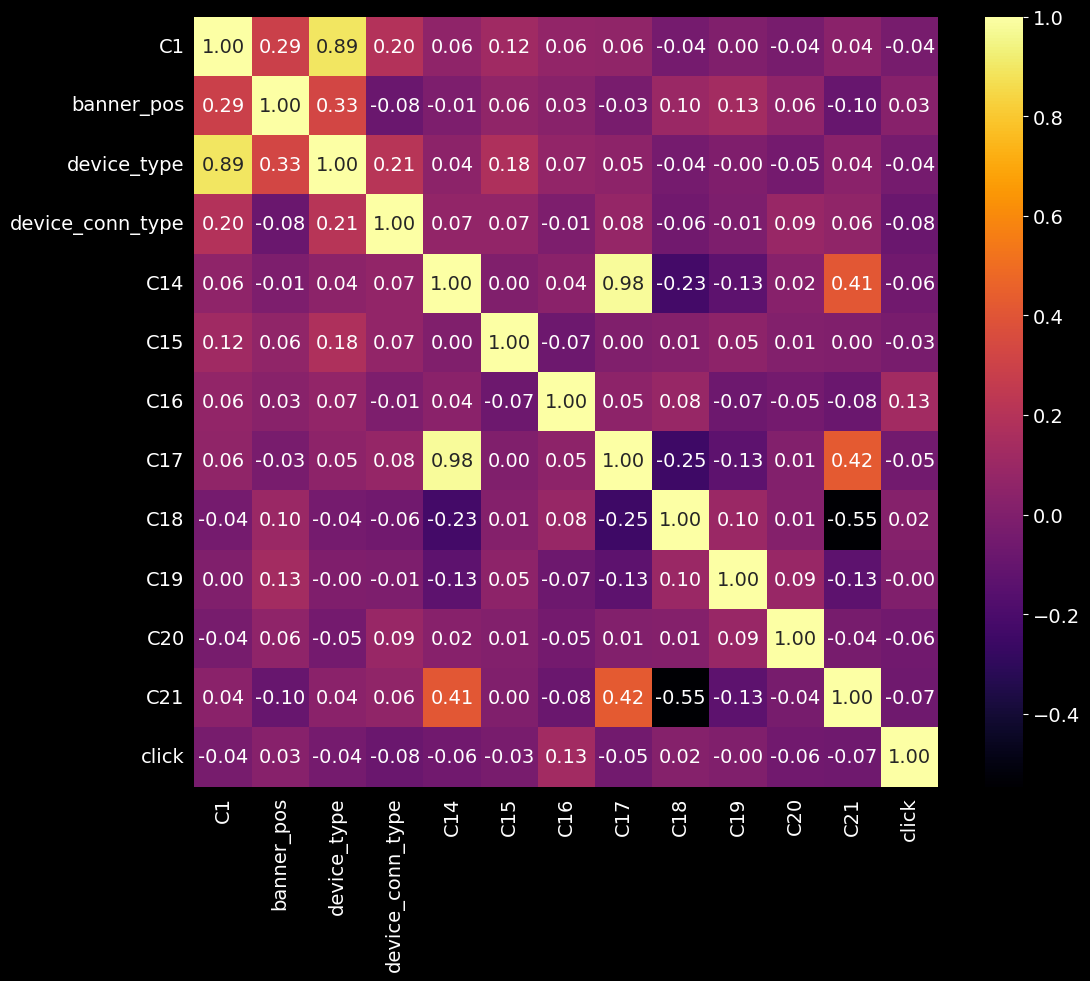

In [22]:
codes = ['C1' , 'banner_pos' , 'device_type' , 'device_conn_type' , 'C14' , 'C15' , 'C16' , 'C17' , 'C18' , 'C19' , 'C20' , 'C21' , 'click']
corr = df[codes].astype(float).corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr , annot=True , fmt='.2f' , cmap='inferno')
plt.show()

### C14 and C17 : 0.98. C17 is a group of C14 (every C14 has exactly one C17) , so they repeat each other.
### C1 and device_type : 0.89. C1 is a relabelled device_type.
### No single code is strongly correlated with click (the largest is C16 at 0.13).

### Key findings
### 1. 17% CTR in every split , mild imbalance.
### 2. Every feature is a category , many with thousands of levels. device_id and device_ip identify users and are not useful as categories.
### 3. Website ads beat app ads (20% vs 12%) , and device type , connection type and site category show big CTR gaps.
### 4. Hour and weekday move CTR only a little.
### 5. C14 / C17 and C1 / device_type repeat each other , one of each pair can go.